# Predicting Customer Churn for a Telecom Provider
**DSAI501 – Group Project (Option A)**

**Part 1** – Data loading, cleaning, feature engineering and exploratory data analysis (EDA)  
**Part 2** – Modelling (logistic regression vs random forest), evaluation, cutoff choice, fairness check and business recommendations

Dataset: *Telco Customer Churn* (IBM sample data, published on Kaggle by BlastChar):
https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Goal: get the raw data into a clean, model-ready shape, find the patterns that drive churn, then build and compare models
that predict which customers will churn – and turn the results into business recommendations.

## 1. Setup and loading the data

In [1]:
# Libraries we use in this part
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)   # all charts are also saved here for the report

# The CSV exactly as downloaded from Kaggle, saved in the data/ folder
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. First look at the data
Each row is one customer. The target is **Churn** (Yes = the customer left within the last month).
The other columns describe the customer (gender, senior citizen, partner, dependents), their account
(tenure in months, contract, billing, payment method, charges) and the services they use.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# Summary of the numeric columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
# How many customers churned? (this is our target)
churn_counts = df["Churn"].value_counts()
print(churn_counts)
print("\nChurn rate: {:.1%}".format((df["Churn"] == "Yes").mean()))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn rate: 26.5%


**Observation:** about **26.5%** of customers churned and 73.5% stayed.
The classes are **imbalanced**, so later we can't judge the models on accuracy alone –
a model that says "nobody churns" would already be ~73% accurate but would catch zero churners.
That's why we also look at **precision, recall and F1**.

## 3. Data cleaning

### 3.1 Data types – TotalCharges is stored as text

In [5]:
# TotalCharges should be a number, but pandas read it as text (object).
print(df["TotalCharges"].dtype)

# Find the values that can't be converted to a number
bad = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print("Rows where TotalCharges is not a number:", bad.sum())
df.loc[bad, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

str
Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**What we found:** 11 rows have a blank space instead of a number in TotalCharges.
All 11 have **tenure = 0** – they are brand-new customers who haven't been billed yet.

**Decision:** convert the column to numbers and fill these 11 blanks with **0**, because a customer
with 0 months of tenure has paid 0 in total. We used domain knowledge here instead of the mean/median,
since the mean would invent a bill these customers never received. (Dropping them would also be
acceptable – it's only 0.16% of the data – but there's no reason to lose real customers.)

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
print(df["TotalCharges"].dtype, "| missing left:", df["TotalCharges"].isna().sum())

float64 | missing left: 0


### 3.2 Missing values and duplicates

In [7]:
print("Missing values per column (total):", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Missing values per column (total): 0
Duplicate rows: 0
Duplicate customer IDs: 0


No missing values are left and there are no duplicate rows or duplicate customers, so nothing needs to be removed.

### 3.3 Outliers in the numeric columns

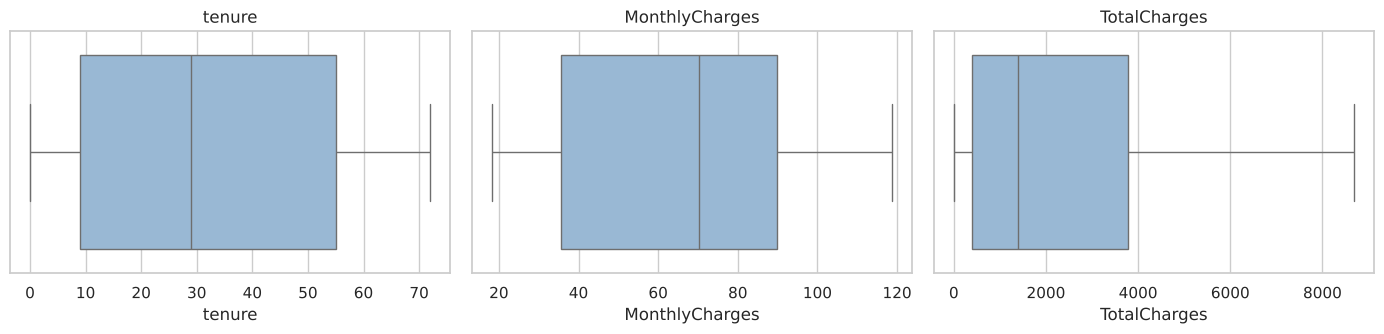

tenure: 0 outliers by the 1.5*IQR rule
MonthlyCharges: 0 outliers by the 1.5*IQR rule
TotalCharges: 0 outliers by the 1.5*IQR rule


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x=df[col], ax=ax, color="#8fb8de")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Check with the 1.5 x IQR rule
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} outliers by the 1.5*IQR rule")

All values are within realistic ranges (tenure 0–72 months, monthly charges about \$18–\$119)
and the 1.5×IQR rule finds **no outliers**, so we keep every row.

### 3.4 Dropping the ID column

In [9]:
# customerID is just an identifier – it has no predictive meaning and would only add noise.
df = df.drop(columns="customerID")
df.shape

(7043, 20)

### 3.5 Making the category labels consistent

In [10]:
# Several service columns have a third value like "No internet service" / "No phone service"
for col in ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies"]:
    print(col, "->", df[col].unique())

MultipleLines -> <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
OnlineSecurity -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup -> <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str


**Decision:** we replace "No internet service" and "No phone service" with **"No"**.
The customer does not have the add-on either way, and the fact that they have no internet/phone
is already captured in the `InternetService` and `PhoneService` columns. Keeping the extra level would
create duplicate dummy variables that all say the same thing (redundant, highly correlated features).

In [11]:
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
df[service_cols] = df[service_cols].replace({"No internet service": "No", "No phone service": "No"})
df[service_cols].apply(lambda s: s.unique())

,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,No,No,Yes,No,No,No,No
1,Yes,Yes,No,Yes,Yes,Yes,Yes


## 4. Exploratory Data Analysis (EDA)
We keep the readable Yes/No labels here so the charts are easy to understand, and convert to numbers afterwards.

In [12]:
# helper: churn rate (%) by a column
def churn_rate(col):
    return (df.groupby(col, observed=True)["Churn"]
              .apply(lambda s: (s == "Yes").mean() * 100)
              .round(1))

### Figure 1 – Overall churn

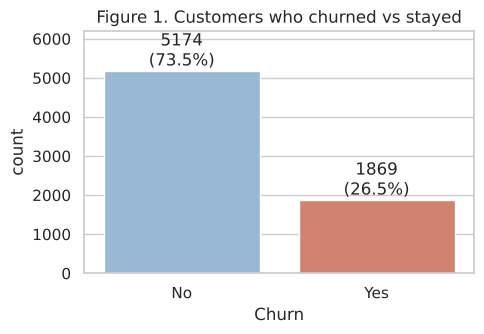

In [13]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x="Churn", data=df, hue="Churn", palette={"No": "#8fb8de", "Yes": "#e07a5f"}, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Figure 1. Customers who churned vs stayed")
ax.set_ylim(0, 6200)
plt.tight_layout(); plt.savefig("figures/fig1_churn_distribution.png", dpi=150); plt.show()

### Figure 2 – Churn rate by contract type

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


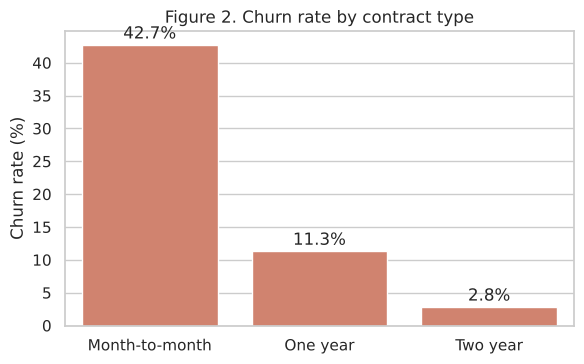

In [14]:
rate = churn_rate("Contract").reindex(["Month-to-month", "One year", "Two year"])
print(rate)
fig, ax = plt.subplots(figsize=(6, 3.8))
sns.barplot(x=rate.index, y=rate.values, color="#e07a5f", ax=ax)
for i, v in enumerate(rate.values):
    ax.text(i, v + 1, f"{v}%", ha="center")
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel("")
ax.set_title("Figure 2. Churn rate by contract type")
plt.tight_layout(); plt.savefig("figures/fig2_churn_by_contract.png", dpi=150); plt.show()

**Insight:** month-to-month customers churn far more (**42.7%**) than one-year (11.3%) and two-year (2.8%) customers.
Contract type looks like the strongest signal in the data. But this is a **correlation, not proof of cause** –
customers who already plan to leave (or are unsure) may simply *choose* flexible contracts.

### Figure 3 – Tenure: new customers leave the most

tenure_group
0-12 m     47.4
13-24 m    28.7
25-48 m    20.4
49-72 m     9.5
Name: Churn, dtype: float64


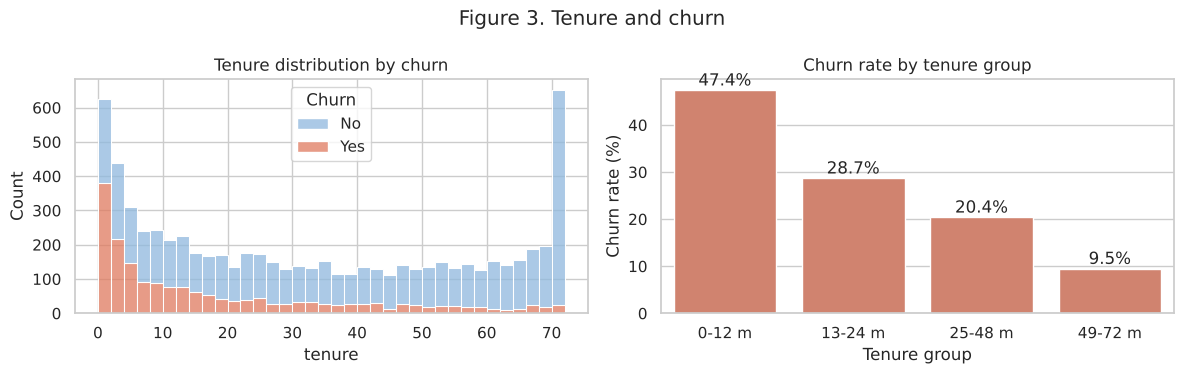

In [15]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
rate = churn_rate("tenure_group")
print(rate)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack",
             palette={"No": "#8fb8de", "Yes": "#e07a5f"}, ax=axes[0])
axes[0].set_title("Tenure distribution by churn")
sns.barplot(x=rate.index.astype(str), y=rate.values, color="#e07a5f", ax=axes[1])
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 1, f"{v}%", ha="center")
axes[1].set_ylabel("Churn rate (%)"); axes[1].set_xlabel("Tenure group")
axes[1].set_title("Churn rate by tenure group")
fig.suptitle("Figure 3. Tenure and churn")
plt.tight_layout(); plt.savefig("figures/fig3_tenure.png", dpi=150); plt.show()

**Insight:** almost half (**47.4%**) of customers in their first year churn, compared with only **9.5%** of customers who have stayed 4+ years.
The first 12 months are the danger zone, so retention efforts should focus on new customers.

### Figure 4 – Monthly charges

       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4


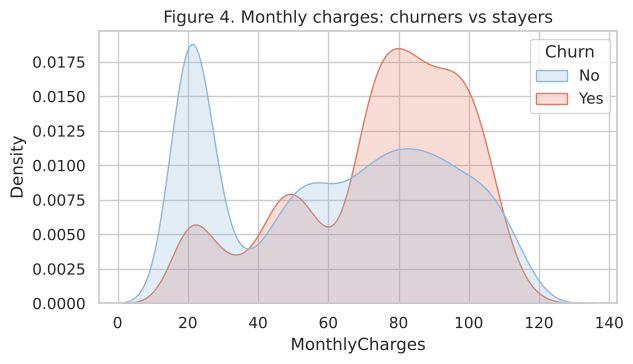

In [16]:
print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False,
            palette={"No": "#8fb8de", "Yes": "#e07a5f"}, ax=ax)
ax.set_title("Figure 4. Monthly charges: churners vs stayers")
plt.tight_layout(); plt.savefig("figures/fig4_monthly_charges.png", dpi=150); plt.show()

**Insight:** churners pay more per month on average (**\$74.4** vs **\$61.3**), and churn is concentrated around \$70–\$105,
which is mostly fibre-optic customers (see Figure 5). Price/value for money may be part of the reason people leave.

### Figure 5 – Internet service, payment method and add-on services

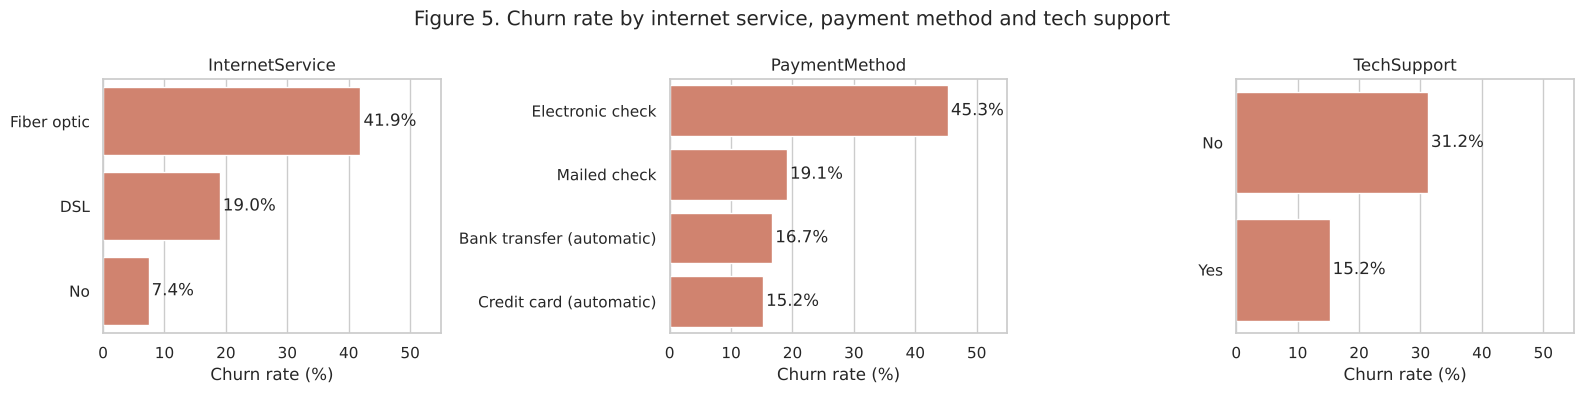

OnlineSecurity {'No': 31.3, 'Yes': 14.6}
PaperlessBilling {'No': 16.3, 'Yes': 33.6}
Partner {'No': 33.0, 'Yes': 19.7}
Dependents {'No': 31.3, 'Yes': 15.5}


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["InternetService", "PaymentMethod", "TechSupport"]):
    rate = churn_rate(col).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, color="#e07a5f", ax=ax)
    for i, v in enumerate(rate.values):
        ax.text(v + 0.5, i, f"{v}%", va="center")
    ax.set_xlabel("Churn rate (%)"); ax.set_ylabel(""); ax.set_title(col)
    ax.set_xlim(0, 55)
fig.suptitle("Figure 5. Churn rate by internet service, payment method and tech support")
plt.tight_layout(); plt.savefig("figures/fig5_services_payment.png", dpi=150); plt.show()

for col in ["OnlineSecurity", "PaperlessBilling", "Partner", "Dependents"]:
    print(col, churn_rate(col).to_dict())

**Insights:**
- **Fibre-optic** customers churn the most (**41.9%** vs 19.0% for DSL). Fibre is the more expensive service, so this links back to price and service quality.
- Customers paying by **electronic check** churn at **45.3%** – roughly three times more than those on automatic bank transfer or credit card (~15–17%). Automatic payments seem to "lock in" customers.
- Customers **without tech support** churn about twice as much (31.2% vs 15.2%), and the same for **online security** (31.3% vs 14.6%). Among internet users only, the gap is even bigger (~42% vs ~15%). Extra services may make customers more "attached" to the provider.
- Customers without a partner or dependents, and customers with paperless billing, also churn more.

### Figure 6 – Fairness check: who are the churners? (senior citizens and gender)

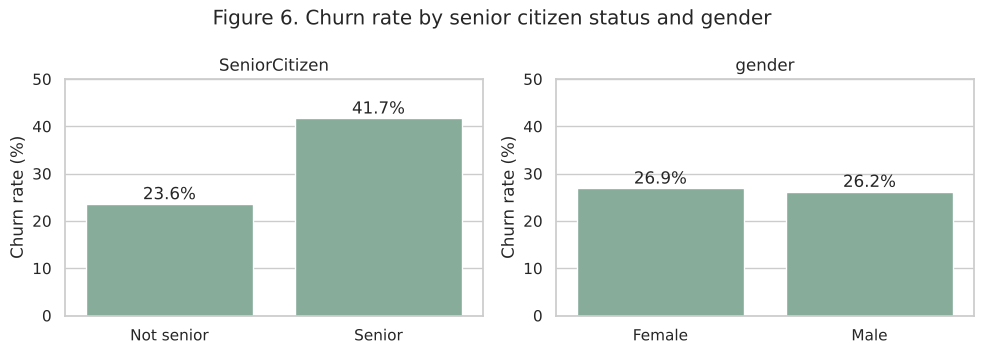

SeniorCitizen
0    0.838
1    0.162
Name: proportion, dtype: float64


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, labels in zip(axes, ["SeniorCitizen", "gender"], [{0: "Not senior", 1: "Senior"}, None]):
    rate = churn_rate(col)
    if labels: rate.index = rate.index.map(labels)
    sns.barplot(x=rate.index.astype(str), y=rate.values, color="#81b29a", ax=ax)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v}%", ha="center")
    ax.set_ylim(0, 50); ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(""); ax.set_title(col)
fig.suptitle("Figure 6. Churn rate by senior citizen status and gender")
plt.tight_layout(); plt.savefig("figures/fig6_fairness.png", dpi=150); plt.show()
print(df["SeniorCitizen"].value_counts(normalize=True).round(3))

**Insight / fairness note:** gender makes almost no difference (26.9% vs 26.2%), but **senior citizens churn much more (41.7% vs 23.6%)**
even though they are only 16% of customers. This means a churn model may **flag seniors more often**. That isn't automatically unfair
(they really do churn more), but the company should make sure seniors receive *helpful* retention offers (e.g. support, simpler plans)
rather than being treated worse, and in Part 2 we check whether the model's errors are similar for both groups.

## 5. Feature engineering (with justification)

In [19]:
data = df.copy()

# (a) Binary Yes/No columns -> 1/0, because models only work with numbers
binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"] + service_cols
for col in binary_cols:
    data[col] = data[col].map({"Yes": 1, "No": 0})

# gender -> 1 = Male, 0 = Female (kept only so we can check fairness; see note below)
data["gender"] = data["gender"].map({"Male": 1, "Female": 0})

# (b) New feature: number of add-on services a customer uses (0-6)
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
data["num_addon_services"] = data[addons].sum(axis=1)

# (c) New feature: automatic payment (bank transfer or credit card) = 1
data["auto_payment"] = data["PaymentMethod"].str.contains("automatic").astype(int)

# (d) New feature: new customer (first 12 months) = 1
data["new_customer"] = (data["tenure"] <= 12).astype(int)

data[["num_addon_services", "auto_payment", "new_customer"]].describe().round(2)

,num_addon_services,auto_payment,new_customer
count,7043.00,7043.00,7043.00
mean,2.04,0.44,0.31
std,1.85,0.50,0.46
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,2.00,0.00,0.00
75%,3.00,1.00,1.00
max,6.00,1.00,1.00


In [20]:
# Do the new features actually separate churners from stayers?
for col in ["num_addon_services", "auto_payment", "new_customer"]:
    print(col, (data.groupby(col)["Churn"].mean() * 100).round(1).to_dict())

num_addon_services {0: 21.4, 1: 45.8, 2: 35.8, 3: 27.4, 4: 22.3, 5: 12.4, 6: 5.3}
auto_payment {0: 34.7, 1: 16.0}
new_customer {0: 17.1, 1: 47.4}


**Why these features?**
- **Yes/No → 1/0:** models can only work with numbers.
- **num_addon_services:** EDA showed customers with security/tech support churn less, so the *total* number of add-ons summarises how "attached" a customer is in one number. Churn falls from 45.8% (1 add-on) to 5.3% (6 add-ons). The 0 group (21.4%) is lower because it includes customers with no internet at all, who churn very little (7.4%).
- **auto_payment:** electronic check users churned ~3× more than automatic payers, so one simple flag captures the payment behaviour.
- **new_customer:** first-year customers churn at 47%, so we flag the risky first 12 months directly.

### 5.1 Correlation matrix – checking for redundant features

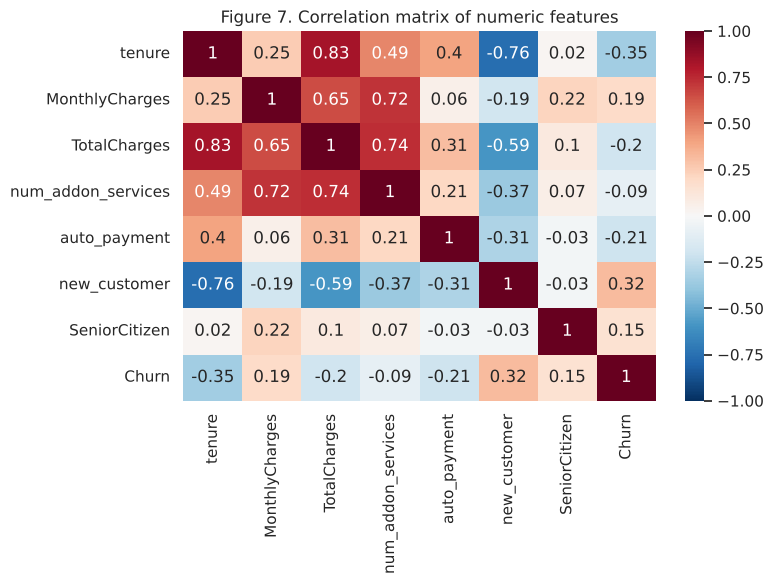

In [21]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_addon_services",
            "auto_payment", "new_customer", "SeniorCitizen", "Churn"]
corr = data[num_cols].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Figure 7. Correlation matrix of numeric features")
plt.tight_layout(); plt.savefig("figures/fig7_correlation.png", dpi=150); plt.show()

**Decision:** `TotalCharges` is strongly correlated with `tenure` (r ≈ 0.83) – which makes sense, because
TotalCharges ≈ tenure × MonthlyCharges. It adds almost no new information and would cause **multicollinearity**
in the logistic regression, so we **drop TotalCharges** and keep tenure and MonthlyCharges.
`tenure_group` (used for the charts) is also dropped because `tenure` and `new_customer` already hold that information.

### 5.2 Dummy variables for the remaining categories

In [22]:
data = data.drop(columns=["TotalCharges", "tenure_group"])

# Contract, InternetService and PaymentMethod have more than 2 categories -> dummy variables.
# drop_first=True gives n-1 dummies per variable (the dropped one is the reference level),
# which avoids perfect multicollinearity.
model_df = pd.get_dummies(data, columns=["Contract", "InternetService", "PaymentMethod"],
                          drop_first=True, dtype=int)
print(model_df.shape)
model_df.head()

(7043, 26)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,num_addon_services,auto_payment,new_customer,Contract_One year,Contract_Two year,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,1,0,1,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,2,0,0,1,0,0,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,2,0,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,3,1,0,1,0,0,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,0,1,0,0,1,0,0,1,0


Reference levels (the dropped dummies): **Month-to-month** contract, **DSL** internet, **Bank transfer** payment.

**Note on scaling:** we do *not* scale here. Scaling (StandardScaler) is done in Part 2 **after** the train/test split,
fitted on the training data only, so no information from the test set leaks into training. Tree models (decision tree,
random forest) don't need scaling at all; logistic regression and KNN do.

**Note on gender/SeniorCitizen:** we keep them so we can test the model for fairness. The team can also try the models
*without* gender to see if accuracy changes – if not, leaving it out is the safer choice for deployment.

## 6. Save the cleaned datasets for Part 2 (modelling)

In [23]:
os.makedirs("data", exist_ok=True)
# readable version (labels, before dummies) - useful for checking
df.drop(columns=["tenure_group"]).to_csv("data/telco_clean.csv", index=False)
# model-ready version (all numeric) - this is the input for the models
model_df.to_csv("data/telco_model_ready.csv", index=False)

print("Saved data/telco_clean.csv      ->", df.drop(columns=['tenure_group']).shape)
print("Saved data/telco_model_ready.csv ->", model_df.shape)
print("Target column: 'Churn' (1 = churned). Churn rate:", round(model_df['Churn'].mean(), 3))
print("All numeric:", model_df.dtypes.apply(lambda t: np.issubdtype(t, np.number)).all())

Saved data/telco_clean.csv      -> (7043, 20)
Saved data/telco_model_ready.csv -> (7043, 26)
Target column: 'Churn' (1 = churned). Churn rate: 0.265
All numeric: True


## 7. Summary of Part 1
**Cleaning:** fixed TotalCharges (text → number, 11 blanks of new customers → 0), confirmed no other missing values,
no duplicates and no outliers, dropped the customer ID, merged "No internet/phone service" into "No".

**Feature engineering:** Yes/No → 1/0, three new features (number of add-on services, automatic payment, new customer),
dropped TotalCharges (r = 0.83 with tenure) and created n−1 dummies for contract, internet service and payment method.

**Main EDA findings:**
1. 26.5% churn → imbalanced, so use precision/recall/F1 and not only accuracy.
2. Month-to-month contracts churn at 42.7% vs 2.8% for two-year contracts.
3. First-year customers churn at 47.4%; churn falls steadily with tenure.
4. Churners pay more per month (\$74 vs \$61); fibre-optic customers churn at 41.9%.
5. Electronic-check payers churn at 45.3% (about 3× automatic payers); customers without tech support / online security churn about 2× more.
6. Senior citizens churn at 41.7% vs 23.6% → check the model for fairness; gender has no real effect.

➡️ **Part 2 (models)** starts from `data/telco_model_ready.csv`.

---
# PART 2 – Modelling, evaluation and business recommendations

**Plan:**
1. Split the data into training (80%) and test (20%) sets.
2. Train two classification models: **logistic regression** (simple, interpretable – the kind banks and telcos like) and **random forest** (many decision trees averaged together, can capture non-linear patterns).
3. Use **5-fold cross-validation on the training set only** to tune the random forest and to choose the cutoff, so the test set stays untouched until the very end.
4. Evaluate both models once on the test set with **accuracy, precision, recall and F1-score** and confusion matrices.
5. Look at feature importance, check fairness, show the model on a test case and save the best model.

## 8. Train/test split

In [24]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import joblib

model_df = pd.read_csv("data/telco_model_ready.csv")
X = model_df.drop(columns="Churn")
y = model_df["Churn"]

# 80% training, 20% test. stratify=y keeps the same churn rate (26.5%) in both sets.
# random_state=42 makes the split reproducible (same split every time we run the notebook).
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Training set:", X_train.shape, "| churn rate:", round(y_train.mean(), 3))
print("Test set:    ", X_test.shape, "| churn rate:", round(y_test.mean(), 3))
print("Number of features:", X.shape[1])

Training set: (5634, 25) | churn rate: 0.265
Test set:     (1409, 25) | churn rate: 0.265
Number of features: 25


The test set (1,409 customers) is **only used once at the end** – like the real exam. All tuning decisions are made on the
training data with cross-validation (the "practice exams").

## 9. Model 1 – Logistic regression
Logistic regression gives each customer a **probability of churning** between 0 and 1 (sigmoid function).
It needs scaled inputs, so we put a **StandardScaler** and the model into one **Pipeline**: the scaler is fitted on the
training data only, which prevents information from the test set leaking into training.

In [25]:
log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])
log_reg.fit(X_train, y_train)
print("Logistic regression trained. Training accuracy:", round(log_reg.score(X_train, y_train), 3))

Logistic regression trained. Training accuracy: 0.807


## 10. Model 2 – Random forest (with tuning)
A random forest builds many decision trees on bootstrap samples, each split looking at a random subset of features, and
**averages** their predictions. A single deep tree overfits, so we tune the two most important stopping rules with
**5-fold cross-validation** on the training data: `max_depth` (how deep each tree can grow) and `min_samples_leaf`
(minimum customers in a leaf). Trees don't need scaling. We score the tuning by **F1**, because the classes are imbalanced.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {"max_depth": [4, 6, 8, 10, None],
              "min_samples_leaf": [1, 5, 10]}
grid = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
                    param_grid, cv=cv, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

rand_forest = grid.best_estimator_
print("Best settings:", grid.best_params_)
print("Cross-validated F1 of best forest:", round(grid.best_score_, 3))
print("Training accuracy:", round(rand_forest.score(X_train, y_train), 3))

Best settings: {'max_depth': 10, 'min_samples_leaf': 5}
Cross-validated F1 of best forest: 0.569
Training accuracy: 0.838


In [27]:
# How the cross-validated F1 changes with tree depth (min_samples_leaf fixed at the best value)
res = pd.DataFrame(grid.cv_results_)
best_leaf = grid.best_params_["min_samples_leaf"]
depth_curve = res[res["param_min_samples_leaf"] == best_leaf][["param_max_depth", "mean_test_score"]]
depth_curve["param_max_depth"] = depth_curve["param_max_depth"].astype(str)
print(depth_curve.rename(columns={"param_max_depth": "max_depth", "mean_test_score": "CV F1"}).round(3).to_string(index=False))

max_depth  CV F1
        4  0.482
        6  0.537
        8  0.564
       10  0.569
      NaN  0.565


Very shallow trees (depth 4) underfit and fully grown trees (None) start to overfit; a medium depth gives the best
cross-validated F1 – the bias–variance trade-off we saw in class.

## 11. Choosing the cutoff with cross-validation (training data only)
By default a customer is predicted to churn if the probability is ≥ 0.5. In churn problems,
**missing a churner (false negative) costs more than contacting a loyal customer (false positive)** – a lost customer
means losing all their future monthly payments, while a retention call or small discount is cheap.
So we compare cutoffs 0.5, 0.4 and 0.3 using **out-of-fold predictions** on the training set.

In [28]:
rows = []
for name, model in [("Logistic regression", log_reg), ("Random forest", rand_forest)]:
    oof_prob = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for cut in [0.5, 0.4, 0.3]:
        pred = (oof_prob >= cut).astype(int)
        rows.append({"Model": name, "Cutoff": cut,
                     "Accuracy": accuracy_score(y_train, pred),
                     "Precision": precision_score(y_train, pred),
                     "Recall": recall_score(y_train, pred),
                     "F1": f1_score(y_train, pred)})
cv_table = pd.DataFrame(rows).round(3)
cv_table

,Model,Cutoff,Accuracy,Precision,Recall,F1
0,Logistic regression,0.5,0.805,0.667,0.532,0.592
1,Logistic regression,0.4,0.793,0.601,0.651,0.625
2,Logistic regression,0.3,0.766,0.542,0.761,0.633
3,Random forest,0.5,0.802,0.672,0.494,0.569
4,Random forest,0.4,0.794,0.608,0.627,0.617
5,Random forest,0.3,0.767,0.543,0.763,0.635


In [29]:
best_row = cv_table.loc[cv_table["F1"].idxmax()]
print("Highest cross-validated F1:", best_row["Model"], "at cutoff", best_row["Cutoff"], "-> F1 =", best_row["F1"])

Highest cross-validated F1: Random forest at cutoff 0.3 -> F1 = 0.635


**Decision:** for both models, lowering the cutoff from 0.5 to 0.3–0.4 raises recall a lot (we catch many more
churners) while precision drops only moderately, so F1 goes up. Accuracy falls slightly, but accuracy is not our main
goal. We choose the cutoff with the highest cross-validated F1 and then test both models once on the test set.

## 12. Final evaluation on the test set

In [30]:
CUTOFF = float(best_row["Cutoff"])

results = []
probs = {}
for name, model in [("Logistic regression", log_reg), ("Random forest", rand_forest)]:
    p = model.predict_proba(X_test)[:, 1]
    probs[name] = p
    for cut in [0.5, CUTOFF]:
        pred = (p >= cut).astype(int)
        results.append({"Model": name, "Cutoff": cut,
                        "Accuracy": accuracy_score(y_test, pred),
                        "Precision": precision_score(y_test, pred),
                        "Recall": recall_score(y_test, pred),
                        "F1": f1_score(y_test, pred)})
test_table = pd.DataFrame(results).drop_duplicates().round(3)
test_table

,Model,Cutoff,Accuracy,Precision,Recall,F1
0,Logistic regression,0.5,0.797,0.651,0.508,0.571
1,Logistic regression,0.3,0.755,0.527,0.749,0.619
2,Random forest,0.5,0.800,0.665,0.495,0.567
3,Random forest,0.3,0.756,0.527,0.773,0.627


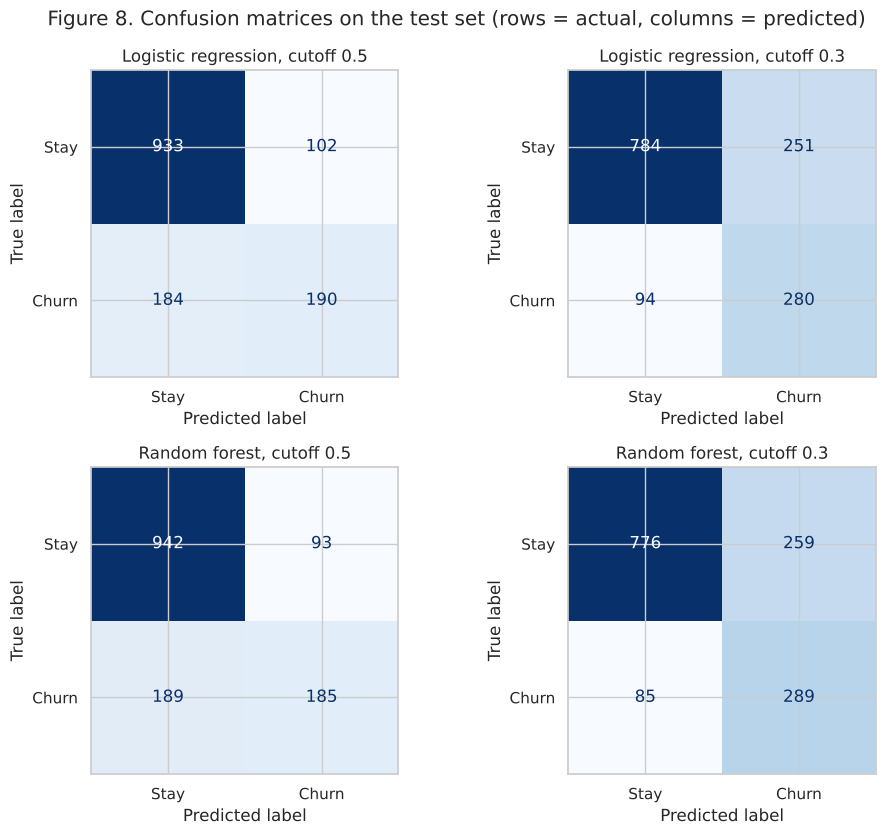

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
for i, name in enumerate(probs):
    for j, cut in enumerate([0.5, CUTOFF]):
        pred = (probs[name] >= cut).astype(int)
        ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Churn"]).plot(
            ax=axes[i, j], cmap="Blues", colorbar=False)
        axes[i, j].set_title(f"{name}, cutoff {cut}")
fig.suptitle("Figure 8. Confusion matrices on the test set (rows = actual, columns = predicted)")
plt.tight_layout(); plt.savefig("figures/fig8_confusion_matrices.png", dpi=150); plt.show()

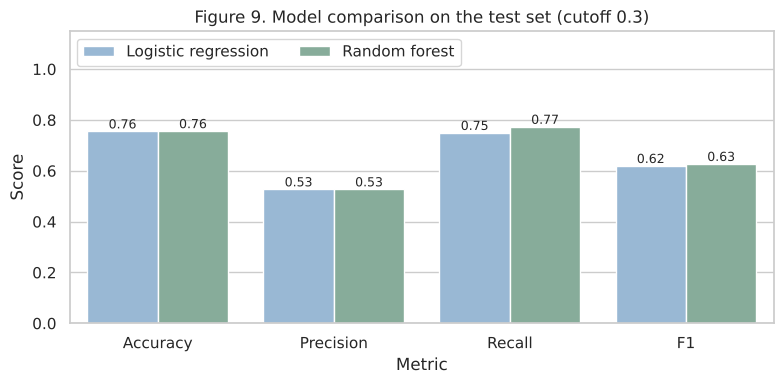

In [32]:
# Bar chart comparing the metrics at the chosen cutoff
plot_df = test_table[test_table["Cutoff"] == CUTOFF].melt(id_vars=["Model", "Cutoff"], var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette=["#8fb8de", "#81b29a"], ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9)
ax.set_ylim(0, 1.15); ax.legend(loc="upper left", ncol=2); ax.set_title(f"Figure 9. Model comparison on the test set (cutoff {CUTOFF})")
plt.tight_layout(); plt.savefig("figures/fig9_model_comparison.png", dpi=150); plt.show()

In [33]:
# Pick the final model: the one with the higher test F1 at the chosen cutoff
final = test_table[test_table["Cutoff"] == CUTOFF].sort_values("F1", ascending=False).iloc[0]
BEST_NAME = final["Model"]
best_model = log_reg if BEST_NAME == "Logistic regression" else rand_forest
print(f"Final model: {BEST_NAME} with cutoff {CUTOFF}")
print(final.to_string())

tn, fp, fn, tp = confusion_matrix(y_test, (probs[BEST_NAME] >= CUTOFF).astype(int)).ravel()
print(f"\nOn the {len(y_test)} test customers: TP={tp}, FP={fp}, FN={fn}, TN={tn}")
print(f"-> caught {tp} of {tp+fn} churners; {fp} loyal customers would also be contacted.")

Final model: Random forest with cutoff 0.3
Model        Random forest
Cutoff                 0.3
Accuracy             0.756
Precision            0.527
Recall               0.773
F1                   0.627

On the 1409 test customers: TP=289, FP=259, FN=85, TN=776
-> caught 289 of 374 churners; 259 loyal customers would also be contacted.


**How to read this:** both models perform very similarly (accuracy around 0.75–0.80). At the default 0.5 cutoff they
miss about half of the churners (recall ≈ 0.5). At the lower cutoff recall rises to roughly three quarters, which is
what a retention team needs, at the cost of more false alarms (lower precision). Overfitting is not a problem:
training and test accuracy are close for both models.

## 13. What drives churn? Feature importance

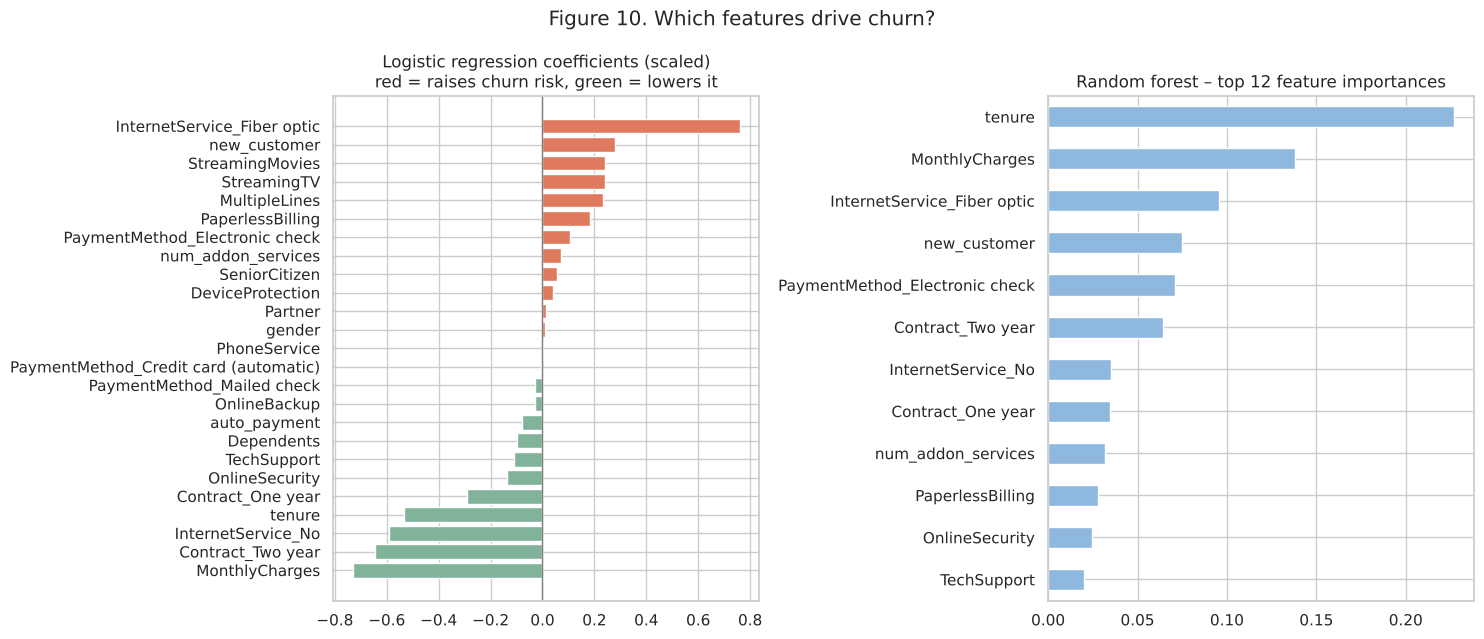

Top 5 features raising churn risk (logistic): ['InternetService_Fiber optic', 'new_customer', 'StreamingMovies', 'StreamingTV', 'MultipleLines']
Top 5 features lowering churn risk (logistic): ['MonthlyCharges', 'Contract_Two year', 'InternetService_No', 'tenure', 'Contract_One year']
Top 5 random forest features: ['tenure', 'MonthlyCharges', 'InternetService_Fiber optic', 'new_customer', 'PaymentMethod_Electronic check']


In [34]:
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=X.columns).sort_values()
importances = pd.Series(rand_forest.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
colors = ["#81b29a" if v < 0 else "#e07a5f" for v in coefs.values]
axes[0].barh(coefs.index, coefs.values, color=colors)
axes[0].axvline(0, color="grey", lw=1)
axes[0].set_title("Logistic regression coefficients (scaled)\nred = raises churn risk, green = lowers it")
importances.tail(12).plot.barh(ax=axes[1], color="#8fb8de")
axes[1].set_title("Random forest – top 12 feature importances")
fig.suptitle("Figure 10. Which features drive churn?")
plt.tight_layout(); plt.savefig("figures/fig10_feature_importance.png", dpi=150); plt.show()

print("Top 5 features raising churn risk (logistic):", list(coefs.sort_values(ascending=False).index[:5]))
print("Top 5 features lowering churn risk (logistic):", list(coefs.index[:5]))
print("Top 5 random forest features:", list(importances.sort_values(ascending=False).index[:5]))

Both models agree with the EDA: **tenure, contract type, fibre-optic internet, being a new customer and electronic-check
payment** are among the strongest signals. Long contracts and long tenure lower the risk.

*Note on MonthlyCharges:* in the random forest it is the 2nd most important feature, but in the logistic regression its
coefficient is negative. That's because monthly charges overlap heavily with fibre optic and the streaming services (they are
what makes the bill high), so the logistic model splits the "price" effect across those columns – a multicollinearity effect.
That's why we read logistic coefficients carefully and confirm them with the random forest and the EDA.

⚠️ **Correlation, not causation.** These features help *predict* churn, but the model can't tell us that they *cause* it.
For example, month-to-month customers churn more, but customers who are already unsure about the provider may simply
*choose* flexible contracts. Forcing everyone onto 2-year contracts would not automatically stop churn – the company would
need to test offers (e.g. an A/B test of a contract-upgrade discount) to find out what really changes behaviour.

## 14. Fairness check
Does the model treat customer groups differently? We compare, on the test set, how often each group is **flagged**
as a churner and how well the model **catches real churners (recall)** in each group.

In [35]:
test_view = X_test.copy()
test_view["actual"] = y_test.values
test_view["predicted"] = (probs[BEST_NAME] >= CUTOFF).astype(int)

def group_report(col, labels):
    out = []
    for val, lab in labels.items():
        g = test_view[test_view[col] == val]
        out.append({"Group": lab, "Customers": len(g),
                    "Actual churn rate": g["actual"].mean(),
                    "Flagged by model": g["predicted"].mean(),
                    "Recall": recall_score(g["actual"], g["predicted"]),
                    "Precision": precision_score(g["actual"], g["predicted"])})
    return pd.DataFrame(out).round(3)

fair = pd.concat([group_report("SeniorCitizen", {0: "Not senior", 1: "Senior"}),
                  group_report("gender", {0: "Female", 1: "Male"})])
fair

,Group,Customers,Actual churn rate,Flagged by model,Recall,Precision
0,Not senior,1187,0.233,0.341,0.728,0.496
1,Senior,222,0.441,0.644,0.898,0.615
0,Female,687,0.281,0.384,0.746,0.545
1,Male,722,0.251,0.393,0.801,0.511


In [36]:
# Does the model need gender at all? Retrain the final model type without gender and compare test F1.
X_train_ng, X_test_ng = X_train.drop(columns="gender"), X_test.drop(columns="gender")
from sklearn.base import clone
model_ng = clone(best_model).fit(X_train_ng, y_train)
pred_ng = (model_ng.predict_proba(X_test_ng)[:, 1] >= CUTOFF).astype(int)
pred_with = (probs[BEST_NAME] >= CUTOFF).astype(int)
print("Test F1 with gender:   ", round(f1_score(y_test, pred_with), 3))
print("Test F1 without gender:", round(f1_score(y_test, pred_ng), 3))

Test F1 with gender:    0.627
Test F1 without gender: 0.629


**Findings:**
- **Gender:** the model flags men and women at almost the same rate, and removing gender barely changes F1 – so gender
  adds nothing and **should be left out** of a deployed model.
- **Senior citizens:** seniors are flagged much more often – but that's because they really do churn more (≈42% vs ≈24%).
  The model is not "wrong" here, but it means seniors will be contacted more. The company must make sure these contacts are
  **helpful** (simpler plans, tech support) and never used to treat seniors worse (e.g. higher prices). Using age-related data
  for marketing should also be checked against company policy and local regulation before deployment.

## 15. The model on a test case
Two examples: one real customer from the test set and one typical "high-risk" profile.

In [37]:
# (a) a real customer from the test set (the first test customer who actually churned)
idx = y_test[y_test == 1].index[0]
one = X_test.loc[[idx]]
p_one = best_model.predict_proba(one)[0, 1]
print(f"Real test customer #{idx}: tenure={one['tenure'].iloc[0]} months, monthly charges=${one['MonthlyCharges'].iloc[0]}")
print(f"Predicted churn probability: {p_one:.2f} -> {'CONTACT (likely to churn)' if p_one >= CUTOFF else 'no action'}"
      f" | actually churned: {'Yes' if y_test.loc[idx] == 1 else 'No'}")

# (b) a typical high-risk profile built from the EDA findings
profile = pd.DataFrame([0] * len(X.columns), index=X.columns).T
profile.loc[0, ["PhoneService", "PaperlessBilling", "new_customer", "InternetService_Fiber optic",
                "PaymentMethod_Electronic check"]] = 1
profile.loc[0, "tenure"] = 3
profile.loc[0, "MonthlyCharges"] = 85.0
p_prof = best_model.predict_proba(profile)[0, 1]
print(f"\nNew customer (3 months), month-to-month, fibre optic, electronic check, no add-ons, $85/month:")
print(f"Predicted churn probability: {p_prof:.2f} -> {'CONTACT' if p_prof >= CUTOFF else 'no action'}")

# same customer but on a two-year contract, paying automatically, with 3 add-ons, 40 months tenure
safe = profile.copy()
safe.loc[0, ["new_customer", "PaymentMethod_Electronic check"]] = 0
safe.loc[0, ["Contract_Two year", "auto_payment", "PaymentMethod_Credit card (automatic)",
             "OnlineSecurity", "TechSupport", "OnlineBackup"]] = 1
safe.loc[0, ["tenure", "num_addon_services"]] = [40, 3]
p_safe = best_model.predict_proba(safe)[0, 1]
print(f"\nLoyal-type customer (40 months, two-year contract, auto-pay, 3 add-ons, $85/month):")
print(f"Predicted churn probability: {p_safe:.2f} -> {'CONTACT' if p_safe >= CUTOFF else 'no action'}")

Real test customer #1639: tenure=17 months, monthly charges=$45.05
Predicted churn probability: 0.36 -> CONTACT (likely to churn) | actually churned: Yes

New customer (3 months), month-to-month, fibre optic, electronic check, no add-ons, $85/month:
Predicted churn probability: 0.69 -> CONTACT

Loyal-type customer (40 months, two-year contract, auto-pay, 3 add-ons, $85/month):
Predicted churn probability: 0.08 -> no action


## 16. Save the final model

In [38]:
joblib.dump({"model": best_model, "cutoff": CUTOFF, "features": list(X.columns)}, "churn_model.joblib")
print("Saved churn_model.joblib")

# how to use it later:
saved = joblib.load("churn_model.joblib")
check = saved["model"].predict_proba(X_test.iloc[:3])[:, 1]
print("Reloaded model works – churn probabilities for 3 test customers:", check.round(2))

Saved churn_model.joblib
Reloaded model works – churn probabilities for 3 test customers: [0.01 0.79 0.08]


## 17. Business view – can the company act on these predictions?

In [39]:
flagged = test_view[test_view["predicted"] == 1]
share_flagged = len(flagged) / len(test_view)
print(f"Share of customers flagged: {share_flagged:.1%}  ->  about {round(share_flagged * 7043):,} of all 7,043 customers")
print(f"Of the flagged customers, {flagged['actual'].mean():.1%} really churn (precision)")

# Prioritise: rank flagged customers by churn probability x monthly charges (= expected monthly revenue at risk)
test_view["churn_prob"] = probs[BEST_NAME]
test_view["revenue_at_risk"] = test_view["churn_prob"] * test_view["MonthlyCharges"]
top = test_view[test_view["predicted"] == 1].sort_values("revenue_at_risk", ascending=False)
top20 = top.head(int(len(top) * 0.2))
print(f"Top 20% of flagged customers by revenue at risk: {len(top20)} customers, "
      f"actual churn rate {top20['actual'].mean():.1%}, avg monthly bill ${top20['MonthlyCharges'].mean():.0f}")

Share of customers flagged: 38.9%  ->  about 2,739 of all 7,043 customers
Of the flagged customers, 52.7% really churn (precision)
Top 20% of flagged customers by revenue at risk: 109 customers, actual churn rate 73.4%, avg monthly bill $89


**Recommendations from the model:**
1. **Don't contact everyone equally.** The model flags a large share of customers. Rank them by *churn probability × monthly bill*
   (revenue at risk) and give the expensive actions (personal callback, bigger discount) to the top group only.
2. **Match the action to the reason:**
   - *New, month-to-month customers* → an onboarding call in the first months and a discount for upgrading to a 1- or 2-year contract.
   - *Fibre-optic customers with high bills* → check service quality and value for money; offer a loyalty price.
   - *Electronic-check payers* → small incentive to switch to automatic payment.
   - *No tech support / online security* → offer a free trial of these add-ons.
   - *Low-risk customers* → **do nothing** (no money wasted).
3. **Test before rolling out.** Because the model shows correlation, not causation, run each offer as an A/B test and measure
   whether churn really drops.

**Is the model ready to deploy?** Not fully yet. It is a good **first version** to rank customers for a pilot retention campaign,
but before full deployment the company should: remove gender, review how seniors are treated, retrain on recent data (this
dataset is a one-off snapshot), check the real cost of an offer vs a lost customer to fine-tune the cutoff, and monitor
performance over time.